# PyWake vs. ZXTM nacelle lidar on T07 (Hill of Towie)

**Goal:** simulate T03 steering its wake past T07 with PyWake and compare the result with the ZXTM lidar on T07. This notebook is the basis for scoring a possible challenge.

**What changed compared with the previous version** (after clarification with ZX Lidars):

| Item | Before | Now | Source |
|---|---|---|---|
| Height of each point | mean height of the scan arc in the segment | **exactly the segment height** (values are interpolated to it) | ZX Lidars |
| Lateral position | mean of the arc samples in the segment | unchanged (confirmed) | ZX Lidars |
| Along-axis position | `Range` from the turbine position | `Range − 0.8 m` (range is measured from the lidar head, 0.8 m behind the rotor) | ZX Lidars, deployment report |
| Which segments exist | scan circle overlaps the segment band | **scan circle reaches the segment height** | ZX Lidars, matches data coverage |
| LOS sign | signed projection | magnitude (always positive) | ZX Lidars |
| Calibration scans | offset could be applied twice | always applied to the raw T01 wind speed | bug fix |

Confirmed and unchanged: 15° cone half-angle, scan circle centred on the lidar head 3.2 m above the rotor axis, `Range` along the cone axis, data already corrected for inclination and roll.

All timestamps are UTC. Run from top to bottom after a kernel restart.

## 1. Settings

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyproj import Transformer

from py_wake.deflection_models.jimenez import JimenezWakeDeflection
from py_wake.flow_map import HorizontalGrid, Points
from py_wake.literature.gaussian_models import Bastankhah_PorteAgel_2014
from py_wake.site import UniformSite
from py_wake.site.shear import PowerShear
from py_wake.wind_turbines.generic_wind_turbines import GenericWindTurbine

from hot_open.fastlog_helpers import load_hot_fl_data
from hot_open.lidar_helpers import load_zx_lidar_fl_data
from hot_open.settings import get_data_dir, get_filestore_dir
from hot_open.sourcing_data import ensure_hot_data_files

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

# Period (same as the reference figure in the RES presentation)
START = pd.Timestamp("2026-02-20 00:00", tz="UTC")
END_EXCL = pd.Timestamp("2026-02-20 04:30", tz="UTC")
FREQ = "1min"                       # averaging interval

# Wake model and inflow
WAKE_K = 0.04                       # wake expansion (PyWake doc example: 0.0324555)
TI = 0.1
SHEAR_ALPHA = 0.2                   # power-law shear exponent
HUB_H = 59.0
ROTOR_R = 41.0
WS_FACTOR = 1.0                     # inflow correction: ws = ws_T01 * WS_FACTOR + WS_ADD
WS_ADD = 0.0

# Optional filter on the T03 -> T07 steering window
APPLY_WD_FILTER = False
WD_WINDOW = (192.0, 224.0)

# ZXTM geometry (confirmed by ZX Lidars)
RANGES_M = [85.0, 126.0, 208.0]
HEIGHTS_M = [26.2, 42.6, 59.0, 75.4, 91.8]   # rotor segment heights above T07 ground
SLICE_HALF = 8.2                             # half segment height (82 m / 5 / 2)
SIDES = ["Right", "Left"]                    # as seen from the lidar looking upwind
HALF_ANGLE_DEG = 15.0                        # cone half-angle
LIDAR_ABOVE_HUB_M = 3.2                      # lidar head above rotor axis
LIDAR_SETBACK_M = 0.8                        # lidar head behind rotor plane
LIDAR_Z = HUB_H + LIDAR_ABOVE_HUB_M          # scan circle centre height

# REWS rule
MIN_HEIGHTS = 3                              # per interval: >= 3 segments incl. hub height

# Dynamic Yaw fastlog tags (true north)
YAW = "computed_driver_pre_processed_yaw_direction_true_degrees"
WD = "computed_core_post_processed_consensus_wind_direction_true_degrees"
TOGGLE = "computed_driver_post_processed_toggle_state"
WS_OFFSET = "computed_core_post_processed_core_wake_steering_offset_degrees"

LOS_COL = "{side} LOS Speed (m/s) at Rotor Segment Height {h}m"
KEYS = ["time", "range", "height", "side"]

c:\Users\ryan.feusi\hill-of-towie-open-source-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Wind farm setup

Turbine positions from the metadata, projected to UTM zone 30N with the origin at the south-west corner. They match the RES FLORIS configuration to within 0.5 m. PyWake treats these positions as rotor centres (nacelle overhang neglected).

`GenericWindTurbine` approximates the Siemens SWT-2.3-VS-82 from diameter, hub height and rated power.

In [2]:
ensure_hot_data_files(["Hill_of_Towie_turbine_metadata.csv"])
meta = pd.read_csv(get_data_dir() / "Hill_of_Towie_turbine_metadata.csv")
names = meta["Turbine Name"].to_list()

transformer = Transformer.from_crs("EPSG:4326", "EPSG:32630", always_xy=True)
utm_x, utm_y = transformer.transform(meta["Longitude"].to_numpy(), meta["Latitude"].to_numpy())
x = utm_x - utm_x.min()
y = utm_y - utm_y.min()

i03, i07 = names.index("T03"), names.index("T07")
x07, y07 = x[i07], y[i07]

swt23 = GenericWindTurbine(name="SWT-2.3-VS-82", diameter=2 * ROTOR_R, hub_height=HUB_H,
                           power_norm=2300, turbulence_intensity=TI)

INFO hot_open.sourcing_data: ensure_hot_data_files: all 1 requested files already present at C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\data (and no missing small files in cached metadata), skipping download


## 3. Turbine data (fastlog), averaged to `FREQ`

- Directions use the Dynamic Yaw `_true_degrees` tags (Siemens tags are in turbine north).
- `load_hot_fl_data` needs the Filestore folder (`get_filestore_dir()`).
- Directions are averaged as unit vectors.
- T03 yaw misalignment = wind direction − yaw direction (positive = counter-clockwise, PyWake convention).
- Inflow for the whole farm: T01 nacelle wind speed and consensus wind direction.

In [3]:
fl = load_hot_fl_data(data_dir=get_filestore_dir(), wtg_numbers=[1, 3, 7],
                      start_dt=START, end_dt_excl=END_EXCL, extra_tags=[YAW, WD, TOGGLE, WS_OFFSET])


def circ_mean_resample(series, freq):
    rad = np.deg2rad(series)
    return np.rad2deg(np.arctan2(np.sin(rad).resample(freq).mean(),
                                 np.cos(rad).resample(freq).mean())) % 360


def circ_diff(a, b):
    return (a - b + 180) % 360 - 180


m = pd.DataFrame({
    "ws_t01": fl[("T01", "AcWindSp_AcWindSp")].resample(FREQ).mean(),
    "wd_t01": circ_mean_resample(fl[("T01", WD)], FREQ),
    "wd_t03": circ_mean_resample(fl[("T03", WD)], FREQ),
    "yaw_t03": circ_mean_resample(fl[("T03", YAW)], FREQ),
    "yaw_t07": circ_mean_resample(fl[("T07", YAW)], FREQ),
    "toggle_t03": fl[("T03", TOGGLE)].resample(FREQ).mean(),
})
m["yaw_mis_t03"] = circ_diff(m["wd_t03"], m["yaw_t03"])
m = m.dropna(subset=["ws_t01", "wd_t01", "yaw_mis_t03", "yaw_t07"])
m["toggle_on"] = m["toggle_t03"] > 0.5
print(f"{len(m)} intervals, {m['toggle_on'].sum()} with steering on")

INFO hot_open.fastlog_helpers: Reading: C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\cache\fl_resampled\HOT\2304510\20260220_EIlqz_Z3Vc3ki-UJiOMVKhMeDnJLhA3m.parquet
INFO hot_open.fastlog_helpers: Reading: C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\cache\fl_resampled\HOT\2304512\20260220_OXg6c4tKlhtGN-YBZ90MA9rBoixaCNpU.parquet
INFO hot_open.fastlog_helpers: Reading: C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\cache\fl_resampled\HOT\2304516\20260220_Fb8AESKTyNWUf-OuDVGMiizyMgkYjxdx.parquet


267 intervals, 130 with steering on


## 4. PyWake simulation

Bastankhah & Porté-Agel (2014) Gaussian wake with Jiménez deflection, uniform inflow with power-law shear, time-series mode (one case per interval). Only T03 gets its measured yaw misalignment. Two runs: with steering (`sim_steer`) and with all turbines aligned (`sim_ref`).

In [4]:
def make_model(k=WAKE_K, ti=TI, alpha=SHEAR_ALPHA):
    site = UniformSite(p_wd=[1], ti=ti, shear=PowerShear(h_ref=HUB_H, alpha=alpha))
    return Bastankhah_PorteAgel_2014(site, swt23, k=k, deflectionModel=JimenezWakeDeflection())


time = m.index.tz_convert(None).to_numpy()
wd_in = m["wd_t01"].to_numpy()
ws_raw = m["ws_t01"].to_numpy()                                  # measured, unchanged


def inflow(ws_factor=WS_FACTOR, ws_add=WS_ADD):
    return np.clip(ws_raw * ws_factor + ws_add, 0.1, None)


yaw = np.zeros((len(x), len(m)))
yaw[i03, :] = m["yaw_mis_t03"].to_numpy()

wf_model = make_model()
sim_steer = wf_model(x, y, wd=wd_in, ws=inflow(), time=time, yaw=yaw, tilt=0)
sim_ref = wf_model(x, y, wd=wd_in, ws=inflow(), time=time, yaw=np.zeros_like(yaw), tilt=0)

## 5. ZXTM data

- `load_zx_lidar_fl_data` needs `get_data_dir() / "lidar_data"`.
- Sentinels 9987–9999 are removed (`remove_bad_values` only handles 9999 and 9991).
- Each row is one ~1 s aggregate at **one** range, with 10 LOS values (5 segments × 2 sides). Heights are already corrected for inclination and roll.

In [5]:
zxtm = load_zx_lidar_fl_data(data_dir=get_data_dir() / "lidar_data", lidar_unit_id="5060",
                             start_dt=START, end_dt_excl=END_EXCL, remove_bad_values=True)
num = zxtm.select_dtypes(include="number").columns
zxtm[num] = zxtm[num].mask((zxtm[num] >= 9987) & (zxtm[num] <= 9999))

los_cols = [LOS_COL.format(side=s, h=h) for s in SIDES for h in HEIGHTS_M]
coverage = zxtm.groupby("Range (m)")[los_cols].count()
coverage.T

INFO hot_open.sourcing_data: ensure_extracted: lidar_data.zip already extracted (sentinel C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\data\lidar_data\timeseries present), skipping
INFO hot_open.lidar_helpers: Reading 1 fastlog parquet files from C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\data\lidar_data\timeseries\5060
Reading 5060 fastlog parquet files: 100%|██████████| 1/1 [00:00<00:00,  4.34it/s]
INFO hot_open.lidar_helpers: Writing: C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\cache\lidar_raw\5060_20260220000000_20260220043000.parquet
INFO hot_open.lidar_helpers: Reading: C:\Users\ryan.feusi\temp\hill-of-towie-open-source-analysis\cache\lidar_raw\5060_20260220000000_20260220043000.parquet


Range (m),10,48,64,85,126,208
Right LOS Speed (m/s) at Rotor Segment Height 26.2m,0,0,0,0,24,775
Right LOS Speed (m/s) at Rotor Segment Height 42.6m,0,0,2,1527,1498,1300
Right LOS Speed (m/s) at Rotor Segment Height 59.0m,3,1756,1819,1819,1737,1393
Right LOS Speed (m/s) at Rotor Segment Height 75.4m,0,1346,2210,2125,2001,1642
Right LOS Speed (m/s) at Rotor Segment Height 91.8m,0,0,0,0,2195,2029
Left LOS Speed (m/s) at Rotor Segment Height 26.2m,0,0,0,0,24,775
Left LOS Speed (m/s) at Rotor Segment Height 42.6m,0,0,2,1527,1498,1300
Left LOS Speed (m/s) at Rotor Segment Height 59.0m,3,1756,1819,1819,1737,1393
Left LOS Speed (m/s) at Rotor Segment Height 75.4m,0,1346,2210,2125,2001,1642
Left LOS Speed (m/s) at Rotor Segment Height 91.8m,0,0,0,0,2195,2029


## 6. Geometry of the measurement points

Confirmed by ZX Lidars:

- At range `R` the scan is a circle of radius `R·tan(15°)`, centred on the lidar head (3.2 m above the rotor axis).
- `Range` is measured along the cone axis **from the lidar head**, which is 0.8 m behind the rotor plane. A reported 150 m is 149.2 m ahead of the rotor.
- Each LOS value is **interpolated to exactly the segment height**. A segment only has a value if the circle reaches that height.
- Its **lateral position is the mean of the positions of the samples** used: the part of the scan circle inside the segment band (± 8.2 m) on that side. Scan samples are spread evenly around the circle.

The LOS direction is the mean direction of those samples: `c_axis = R / slant`, `c_side = lateral / slant` with `slant = R / cos(15°)`.

In [6]:
TAN_HALF = np.tan(np.deg2rad(HALF_ANGLE_DEG))
REWS_HEIGHTS = {r: [h for h in HEIGHTS_M if abs(h - LIDAR_Z) <= r * TAN_HALF] for r in RANGES_M}


def zxtm_points(yaw_deg, n_samples=720):
    # Positions and mean beam directions of all reachable ZXTM values (range x segment x side)
    yr = np.deg2rad(yaw_deg)
    fwd = np.array([np.sin(yr), np.cos(yr)])          # along the cone axis (upwind)
    right = np.array([np.cos(yr), -np.sin(yr)])       # right, looking upwind from the lidar
    theta = np.linspace(0, 2 * np.pi, n_samples, endpoint=False)
    pts = []
    for r in RANGES_M:
        rho = r * TAN_HALF
        slant = np.hypot(r, rho)
        along = r - LIDAR_SETBACK_M                    # distance ahead of the rotor plane
        lat_s = rho * np.cos(theta)
        z_s = LIDAR_Z + rho * np.sin(theta)
        for h in REWS_HEIGHTS[r]:
            in_band = np.abs(z_s - h) <= SLICE_HALF
            for side, sign in (("Right", 1), ("Left", -1)):
                lateral = lat_s[in_band & (sign * lat_s > 0)].mean()
                pos = np.array([x07, y07]) + along * fwd + lateral * right
                pts.append({"range": r, "height": h, "side": side, "x": pos[0], "y": pos[1], "z": h,
                            "c_axis": r / slant, "c_side": lateral / slant})
    return pts


print("Segments reached by the scan circle:", REWS_HEIGHTS)
print("Segments with data (> 1 % of rows):",
      {r: [h for h in HEIGHTS_M if coverage.loc[r, LOS_COL.format(side="Right", h=h)] > 0.01 * coverage.loc[r].max()]
       for r in RANGES_M})

Segments reached by the scan circle: {85.0: [42.6, 59.0, 75.4], 126.0: [42.6, 59.0, 75.4, 91.8], 208.0: [26.2, 42.6, 59.0, 75.4, 91.8]}
Segments with data (> 1 % of rows): {85.0: [42.6, 59.0, 75.4], 126.0: [26.2, 42.6, 59.0, 75.4, 91.8], 208.0: [26.2, 42.6, 59.0, 75.4, 91.8]}


### Check: arc mean vs. Zacks' quick approximation

ZX Lidars suggested as an approximation the midpoint of the chord between the circle points at the segment boundaries (± 8.2 m). Both should be close; the arc mean is used.

In [7]:
def chord_mid(r, h):
    rho = r * TAN_HALF
    lat = lambda z: np.sqrt(rho**2 - np.clip(z - LIDAR_Z, -rho, rho) ** 2)
    return (lat(h - SLICE_HALF) + lat(h + SLICE_HALF)) / 2


geo = pd.DataFrame(zxtm_points(210.0))
geo = geo[geo["side"] == "Right"].assign(lateral=lambda d: d["c_side"] * np.hypot(d["range"], d["range"] * TAN_HALF))
geo["chord_mid"] = [chord_mid(r, h) for r, h in zip(geo["range"], geo["height"])]
geo[["range", "height", "lateral", "chord_mid"]].round(2)

,range,height,lateral,chord_mid
0,85.0,42.6,10.88,9.86
2,85.0,59.0,21.99,20.97
4,85.0,75.4,16.43,15.01
6,126.0,42.6,26.36,25.47
8,126.0,59.0,33.26,32.58
10,126.0,75.4,30.48,29.75
12,126.0,91.8,13.93,13.06
14,208.0,26.2,41.79,41.13
16,208.0,42.6,51.90,51.43
18,208.0,59.0,55.44,55.03


### Check: instrument inclination

The data are corrected to zero inclination, but the real scan circle moves with the nacelle tilt under load (this is why some segments have data only part of the time). This cell shows how far the circle centre would move at each range. If the shift is small compared with the wake width, the nominal geometry is good enough.

In [8]:
INCL = "Inclination Angle Mean (deg)"
if INCL in zxtm.columns:
    inc = zxtm[INCL].dropna()
    print(f"Inclination: mean {inc.mean():+.2f} deg, std {inc.std():.2f} deg, 1-99 % [{inc.quantile(0.01):+.2f}, {inc.quantile(0.99):+.2f}]")
    for r in RANGES_M:
        print(f"  {r:>5.0f} m: centre shift at mean {r * np.tan(np.deg2rad(inc.mean())):+.2f} m, "
              f"per 1 std {r * np.tan(np.deg2rad(inc.std())):.2f} m")
else:
    print(f"Column '{INCL}' not found")

Inclination: mean +0.35 deg, std 0.25 deg, 1-99 % [-0.44, +1.02]
     85 m: centre shift at mean +0.52 m, per 1 std 0.37 m
    126 m: centre shift at mean +0.77 m, per 1 std 0.54 m
    208 m: centre shift at mean +1.27 m, per 1 std 0.89 m


## 7. PyWake at the measurement points, projected to LOS

For each interval: compute the point positions from the T07 yaw direction, evaluate PyWake there with `Points`, project onto the beam:

`LOS = | U · (c_axis · cos Δ + c_side · sin Δ) |`, with `Δ = wind direction − T07 yaw direction`.

PyWake has no vertical wind component. The geometry is computed once and reused for all runs. This cell is the slowest part.

In [9]:
geom = [pd.DataFrame(zxtm_points(yv)) for yv in m["yaw_t07"]]


def los_at_zxtm(sim):
    parts = []
    for i_t, (ts, g) in enumerate(zip(m.index, geom)):
        ws = sim.flow_map(grid=Points(g["x"].to_numpy(), g["y"].to_numpy(), g["z"].to_numpy()),
                          time=time[i_t]).WS_eff.values.ravel()
        d = np.deg2rad(wd_in[i_t] - m["yaw_t07"].iloc[i_t])
        out = g[["range", "height", "side"]].copy()
        out["time"] = ts
        out["los"] = np.abs(ws * (g["c_axis"] * np.cos(d) + g["c_side"] * np.sin(d)))
        parts.append(out)
    return pd.concat(parts, ignore_index=True)


los_sim = (los_at_zxtm(sim_steer).rename(columns={"los": "los_steer"})
           .merge(los_at_zxtm(sim_ref).rename(columns={"los": "los_ref"}), on=KEYS))

## 8. Measured LOS values

Averaged per range, side and segment over `FREQ` (filter on range first, then average).

In [10]:
meas = []
for r in RANGES_M:
    sub = zxtm[zxtm["Range (m)"] == r]
    for side in SIDES:
        for h in REWS_HEIGHTS[r]:
            s = sub[LOS_COL.format(side=side, h=h)].resample(FREQ).mean().reindex(m.index)
            meas.append(pd.DataFrame({"time": m.index, "range": r, "height": h, "side": side,
                                      "los_meas": s.to_numpy()}))
meas_df = pd.concat(meas, ignore_index=True)

los_all = los_sim.merge(meas_df, on=KEYS, how="left")
print(f"{los_all['los_meas'].notna().mean():.0%} of point-intervals have a measurement")

95% of point-intervals have a measurement


## 9. Rotor equivalent wind speed (REWS) from LOS

`REWS = ( Σ (Aᵢ/A) · LOSᵢ³ )^(1/3)` (IEC 61400-12-1 form, applied to LOS).

Rule: per interval, use all segments with a measurement, at least 3 including hub height. The whole rotor (18–100 m) is split between the available heights at the midpoints between them; the outermost heights also cover up to the blade tips. Simulation and measurement get the same segments and weights.

In [11]:
def strip_area(z_lo, z_hi, r=ROTOR_R, hub=HUB_H):
    F = lambda yy: yy * np.sqrt(r**2 - yy**2) + r**2 * np.arcsin(yy / r)
    a, b = np.clip([z_lo - hub, z_hi - hub], -r, r)
    return F(b) - F(a)


def rews_weights(heights):
    h = sorted(heights)
    bounds = [HUB_H - ROTOR_R] + [(h[i] + h[i + 1]) / 2 for i in range(len(h) - 1)] + [HUB_H + ROTOR_R]
    return {hh: strip_area(bounds[i], bounds[i + 1]) / (np.pi * ROTOR_R**2) for i, hh in enumerate(h)}


def compute_rews(df, value_cols):
    out = []
    for (r, side), g in df.groupby(["range", "side"]):
        piv = g.pivot(index="time", columns="height", values=value_cols)
        for ts, ok in piv["los_meas"].notna().iterrows():
            hs = [h for h in REWS_HEIGHTS[r] if ok.get(h, False)]
            if len(hs) < MIN_HEIGHTS or HUB_H not in hs:
                continue
            w = rews_weights(hs)
            rec = {"time": ts, "range": r, "side": side, "n_heights": len(hs)}
            for v in value_cols:
                rec[v.replace("los", "rews")] = sum(w[h] * piv.loc[ts, (v, h)] ** 3 for h in hs) ** (1 / 3)
            out.append(rec)
    return pd.DataFrame(out)


rews_df = compute_rews(los_all, ["los_meas", "los_steer", "los_ref"])
rews_df["toggle_on"] = rews_df["time"].map(m["toggle_on"])
rews_df["wd_ok"] = rews_df["time"].map(m["wd_t01"].between(*WD_WINDOW))
rews_df.groupby(["range", "side"])["n_heights"].value_counts().unstack(fill_value=0)

n_heights      3    4    5
range side                
85.0  Left   264    0    0
      Right  264    0    0
126.0 Left     8  254    0
      Right    8  254    0
208.0 Left     7   59  168
      Right    7   59  168

## 10. Scoring

Per time series (3 ranges × 2 sides): bias, RMSE, and NRMSE = RMSE / mean measured REWS. **Score** = mean of the 6 NRMSE values (each series weighted equally). Lower is better. The split by toggle state shows whether the metric picks up steering.

In [12]:
scored = rews_df[rews_df["wd_ok"]] if APPLY_WD_FILTER else rews_df


def metrics(df, sim_col):
    e = df[sim_col] - df["rews_meas"]
    rmse = np.sqrt((e**2).mean())
    return pd.Series({"n": int(e.notna().sum()), "bias": e.mean(), "rmse": rmse,
                      "nrmse_%": 100 * rmse / df["rews_meas"].mean()})


def per_series(df, sim_col, by=("range", "side")):
    return df.groupby(list(by)).apply(lambda g: metrics(g, sim_col), include_groups=False)


stats = pd.concat({"steer": per_series(scored, "rews_steer"), "ref": per_series(scored, "rews_ref")}, axis=1)
print(f"Score with steering:    {stats[('steer', 'nrmse_%')].mean():.2f} %")
print(f"Score without steering: {stats[('ref', 'nrmse_%')].mean():.2f} %")
stats.round(3)

Score with steering:    22.91 %
Score without steering: 23.44 %


steer                          ref                      
                 n   bias   rmse nrmse_%      n   bias   rmse nrmse_%
range side                                                           
85.0  Left   264.0 -0.445  1.446  21.028  264.0 -0.599  1.520  22.099
      Right  264.0 -0.831  1.756  24.533  264.0 -0.992  1.797  25.101
126.0 Left   262.0 -0.391  1.391  20.246  262.0 -0.515  1.459  21.246
      Right  262.0 -0.990  1.828  24.881  262.0 -1.120  1.849  25.164
208.0 Left   234.0 -0.257  1.306  20.803  234.0 -0.333  1.331  21.203
      Right  234.0 -1.192  1.884  25.960  234.0 -1.227  1.876  25.842

In [13]:
by_toggle = pd.concat({"steer": per_series(scored, "rews_steer", ("range", "side", "toggle_on")),
                       "ref": per_series(scored, "rews_ref", ("range", "side", "toggle_on"))}, axis=1)
by_toggle.xs("nrmse_%", axis=1, level=1).unstack("toggle_on").round(2)

steer           ref       
toggle_on    False  True   False  True 
range side                             
85.0  Left   20.36  21.50  20.41  23.35
      Right  22.05  26.61  21.94  27.70
126.0 Left   19.13  21.09  19.21  22.77
      Right  21.98  27.41  21.73  28.11
208.0 Left   18.87  23.01  18.96  23.74
      Right  21.75  30.92  21.39  31.03

## 11. Plots

### 11.1 REWS time series

Left column = right beam (west for SSW wind), right column = left beam (east), as seen from the lidar looking upwind.

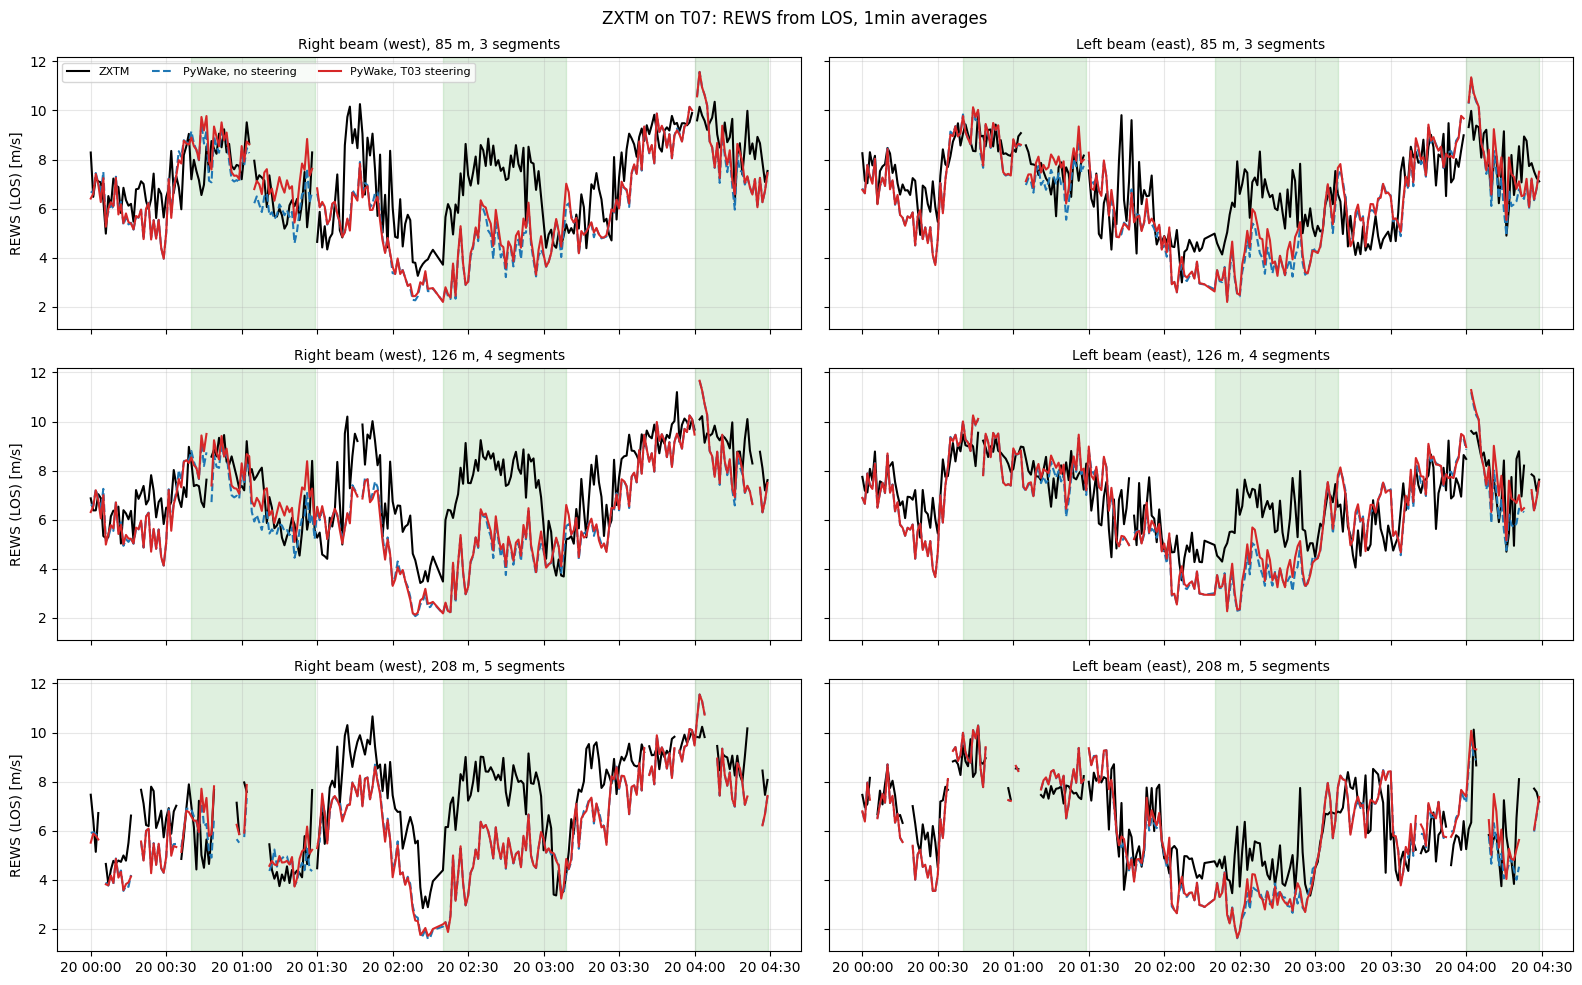

In [14]:
wide = rews_df.pivot_table(index="time", columns=["range", "side"], values=["rews_meas", "rews_ref", "rews_steer"])
toggle_on = m["toggle_on"].reindex(wide.index).fillna(False)
styles = [("rews_meas", dict(color="black"), "ZXTM"),
          ("rews_ref", dict(color="tab:blue", ls="--"), "PyWake, no steering"),
          ("rews_steer", dict(color="tab:red"), "PyWake, T03 steering")]


def shade(ax, index, on):
    ax.fill_between(index, 0, 1, where=on, transform=ax.get_xaxis_transform(), color="tab:green", alpha=0.15)  # type: ignore


fig, axes = plt.subplots(len(RANGES_M), 2, figsize=(16, 10), sharex=True, sharey=True)
for row, r in enumerate(RANGES_M):
    for col, side in enumerate(SIDES):
        ax = axes[row, col]
        for var, st, lab in styles:
            ax.plot(wide.index, wide[(var, r, side)], label=lab, **st)
        shade(ax, wide.index, toggle_on)
        ax.set_title(f"{side} beam ({'west' if side == 'Right' else 'east'}), {r:.0f} m, "
                     f"{len(REWS_HEIGHTS[r])} segments", fontsize=10)
        ax.grid(alpha=0.3)
    axes[row, 0].set_ylabel("REWS (LOS) [m/s]")
axes[0, 0].legend(ncol=3, fontsize=8)
axes[0, 0].margins(x=0)
fig.suptitle(f"ZXTM on T07: REWS from LOS, {FREQ} averages")
fig.tight_layout()
plt.show()

### 11.2 Error decomposition (rolling)

`RMSE² = bias² + spread²`. A large bias with small spread points to a systematic error (e.g. inflow), a large spread with small bias to noise.

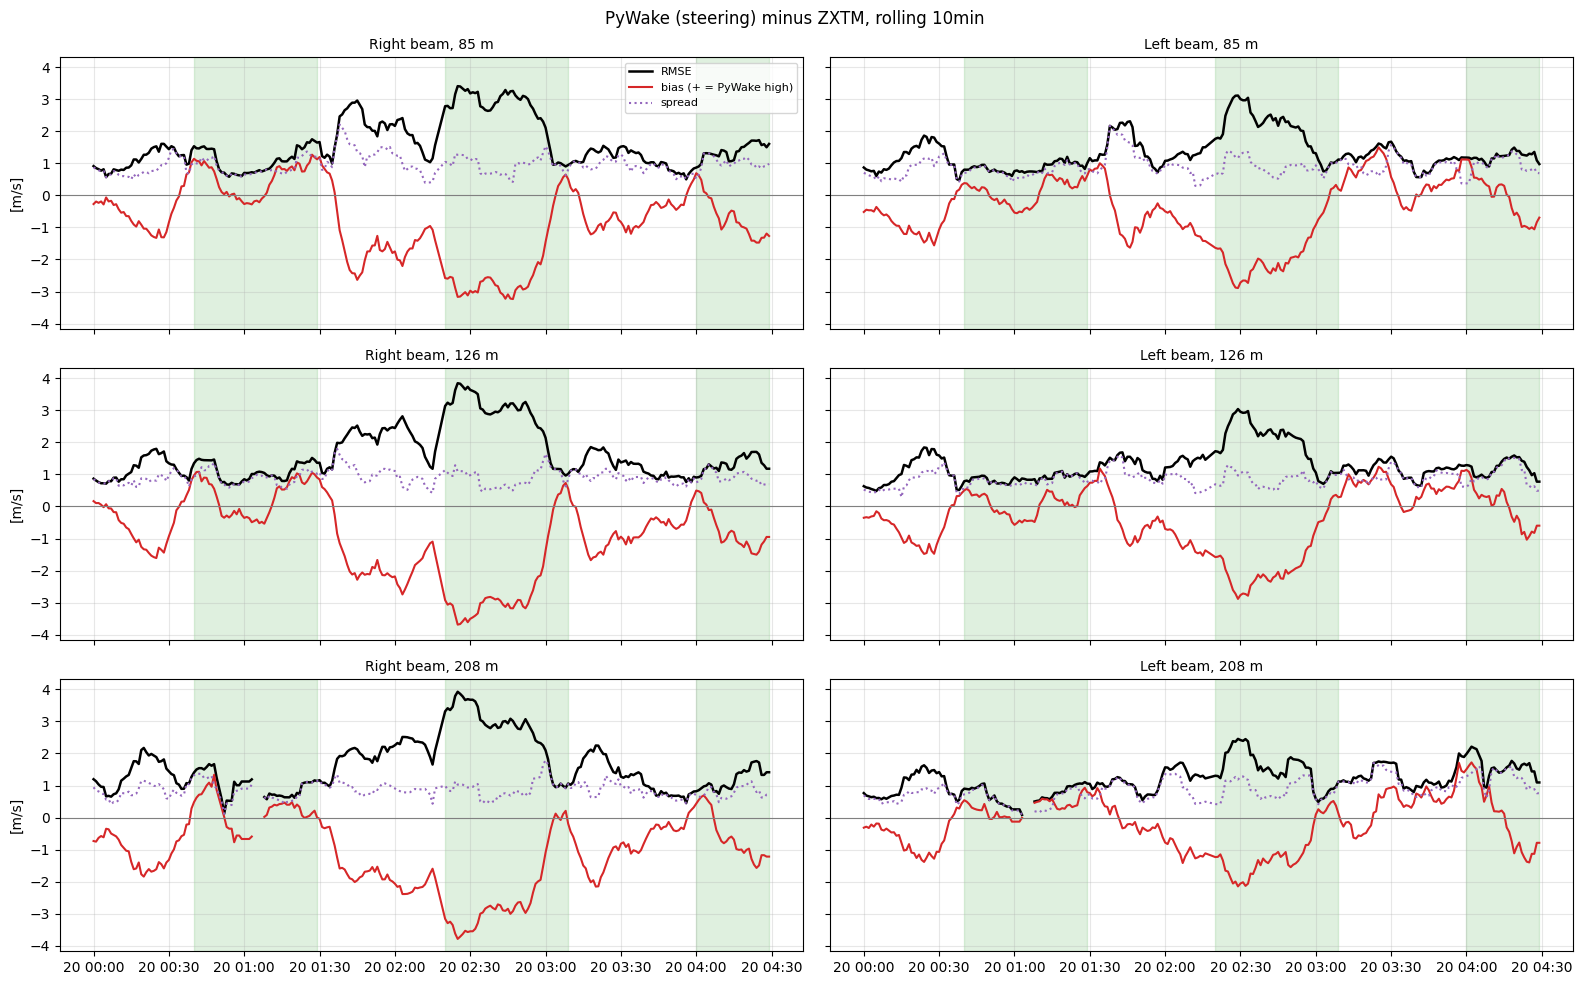

In [15]:
WINDOW = "10min"
err = wide["rews_steer"] - wide["rews_meas"]

fig, axes = plt.subplots(len(RANGES_M), 2, figsize=(16, 10), sharex=True, sharey=True)
for row, r in enumerate(RANGES_M):
    for col, side in enumerate(SIDES):
        ax = axes[row, col]
        roll = err[(r, side)].rolling(WINDOW, center=True, min_periods=3)
        bias, spread = roll.mean(), roll.std(ddof=0)
        ax.plot(bias.index, np.sqrt(bias**2 + spread**2), color="black", lw=1.8, label="RMSE")
        ax.plot(bias.index, bias, color="tab:red", label="bias (+ = PyWake high)")
        ax.plot(spread.index, spread, color="tab:purple", ls=":", label="spread")
        ax.axhline(0, color="grey", lw=0.8)
        shade(ax, wide.index, toggle_on)
        ax.set_title(f"{side} beam, {r:.0f} m", fontsize=10)
        ax.grid(alpha=0.3)
    axes[row, 0].set_ylabel("[m/s]")
axes[0, 0].legend(fontsize=8)
axes[0, 0].margins(x=0)
fig.suptitle(f"PyWake (steering) minus ZXTM, rolling {WINDOW}")
fig.tight_layout()
plt.show()

### 11.3 Vertical profiles at one interval

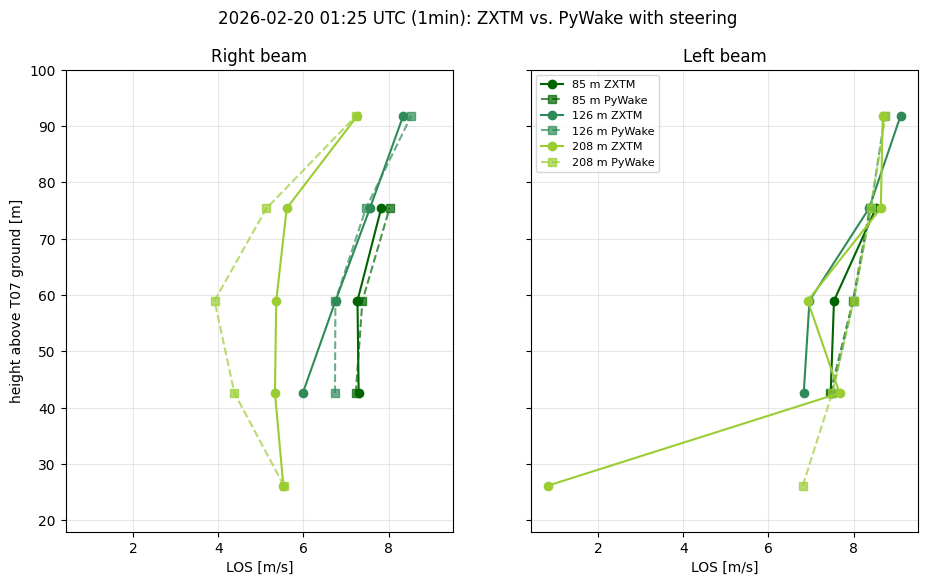

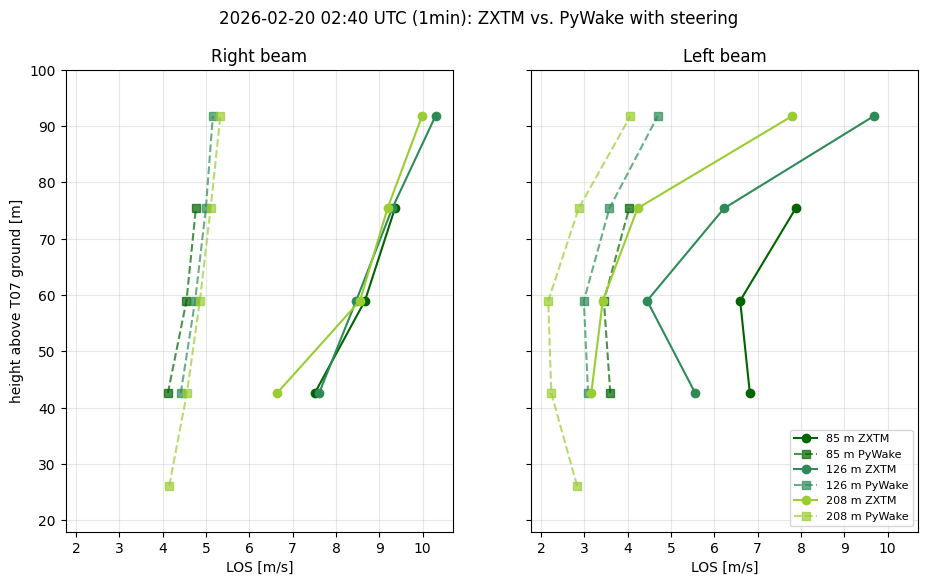

In [16]:
RANGE_COLORS = {85.0: "darkgreen", 126.0: "seagreen", 208.0: "yellowgreen"}


def plot_profiles(t_str):
    snap = los_all[los_all["time"] == pd.Timestamp(t_str, tz="UTC")]
    fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharex=True, sharey=True)
    for ax, side in zip(axes, SIDES):
        for r, c in RANGE_COLORS.items():
            d = snap[(snap["side"] == side) & (snap["range"] == r)].sort_values("height")
            ax.plot(d["los_meas"], d["height"], "o-", color=c, label=f"{r:.0f} m ZXTM")
            ax.plot(d["los_steer"], d["height"], "s--", color=c, alpha=0.7, label=f"{r:.0f} m PyWake")
        ax.set_title(f"{side} beam")
        ax.set_xlabel("LOS [m/s]")
        ax.set_ylim(18, 100)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("height above T07 ground [m]")
    axes[1].legend(fontsize=8)
    fig.suptitle(f"{t_str} UTC ({FREQ}): ZXTM vs. PyWake with steering")
    plt.show()


plot_profiles("2026-02-20 01:25")
plot_profiles("2026-02-20 02:40")

### 11.4 Flow map with the measurement points

WARNING matplotlib.axes._base: Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


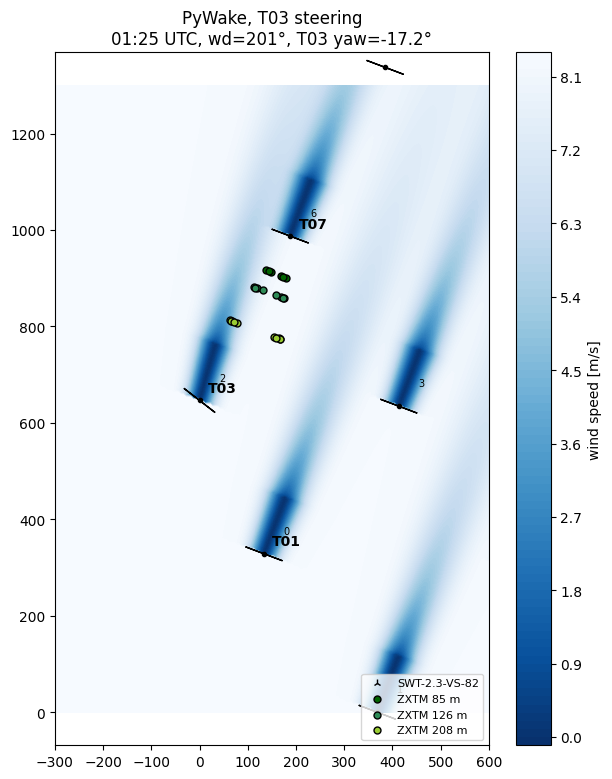

WARNING matplotlib.axes._base: Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


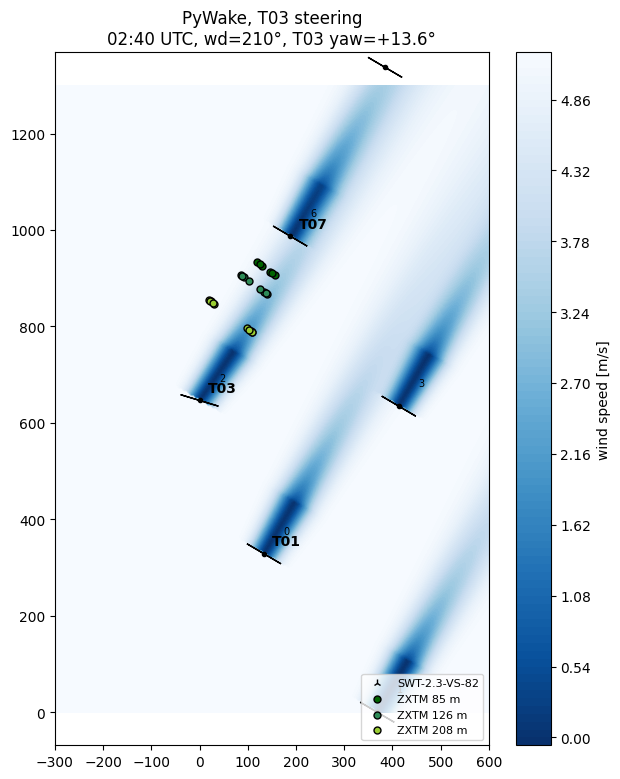

In [17]:
def plot_flowmap(t_str, sim=sim_steer, title="PyWake, T03 steering"):
    ts = pd.Timestamp(t_str, tz="UTC")
    i_t = m.index.get_loc(ts)
    fm = sim.flow_map(grid=HorizontalGrid(x=np.linspace(-300, 600, 180), y=np.linspace(0, 1300, 260)),
                      time=time[i_t])
    fig, ax = plt.subplots(figsize=(7, 9))
    fm.plot_wake_map(ax=ax)
    g = geom[i_t]
    for r, c in RANGE_COLORS.items():
        p = g[g["range"] == r]
        ax.scatter(p["x"], p["y"], color=c, edgecolor="k", s=25, zorder=5, label=f"ZXTM {r:.0f} m")
    for n in ["T01", "T03", "T07"]:
        i = names.index(n)
        ax.annotate(n, (x[i], y[i]), xytext=(6, 6), textcoords="offset points", fontweight="bold")
    ax.set_xlim(-300, 600)
    ax.set_ylim(0, 1300)
    ax.set_aspect("equal")
    ax.legend(fontsize=8, loc="lower right")
    ax.set_title(f"{title}\n{ts:%H:%M} UTC, wd={wd_in[i_t]:.0f}°, T03 yaw={m['yaw_mis_t03'].iloc[i_t]:+.1f}°")
    plt.show()


plot_flowmap("2026-02-20 01:25")
plot_flowmap("2026-02-20 02:40")

## 12. Optional: calibration scans

Each case reruns PyWake and the evaluation (slow). Corrections are always applied to the raw T01 wind speed. A value tuned on this period should be checked on another period before use.

In [19]:
def score_case(ws_factor=1.0, ws_add=0.0, k=WAKE_K):
    sim = make_model(k=k)(x, y, wd=wd_in, ws=inflow(ws_factor, ws_add), time=time, yaw=yaw, tilt=0)
    df = los_at_zxtm(sim).rename(columns={"los": "los_sim"}).merge(meas_df, on=KEYS, how="left")
    rews = compute_rews(df, ["los_meas", "los_sim"])
    rews = rews[rews["time"].map(m["wd_t01"].between(*WD_WINDOW))] if APPLY_WD_FILTER else rews
    return per_series(rews, "rews_sim")["nrmse_%"].mean(), (rews["rews_sim"] - rews["rews_meas"]).mean()


RUN_SCANS = True
if RUN_SCANS:
    for label, cases in [("offset [m/s]", [dict(ws_add=a) for a in (0.0, 0.25, 0.5, 0.75, 1.0)]),
                         ("k", [dict(k=k) for k in (0.03, 0.04, 0.05, 0.06, 0.08)])]:
        for c in cases:
            s, b = score_case(**c)
            print(f"{label} {list(c.values())[0]:>5}: score {s:6.2f} %, bias {b:+.2f} m/s")

offset [m/s]   0.0: score  22.91 %, bias -0.68 m/s
offset [m/s]  0.25: score  21.95 %, bias -0.47 m/s
offset [m/s]   0.5: score  21.39 %, bias -0.26 m/s
offset [m/s]  0.75: score  21.26 %, bias -0.05 m/s
offset [m/s]   1.0: score  21.56 %, bias +0.16 m/s
k  0.03: score  24.09 %, bias -0.84 m/s
k  0.04: score  22.91 %, bias -0.68 m/s
k  0.05: score  22.57 %, bias -0.58 m/s
k  0.06: score  22.56 %, bias -0.51 m/s
k  0.08: score  22.92 %, bias -0.40 m/s


## Open points

- Probe length (CW focus) at 85/126/208 m is not modelled; PyWake is sampled at a point.
- Nacelle overhang: PyWake positions are tower positions; the rotor plane is slightly ahead.
- Inclination under load moves the real scan circle (see check in section 6).
- Shear exponent and TI: take from the ZXTM `FD Vertical Wind Shear Exponent` and spectral TI, or from the ZX300.
- Veer is not modelled.
- Inflow from T01 is too low in some phases; wake depth depends on `k`.
- `FREQ = "10min"` (own averages of the high-resolution data) for less noise.